# Lab 09: ABC on a contaminated Hubble diagram

**ASTR 457, Fall 2026, posted Tue Nov 10, due Tue Nov 17 by noon (fork → PR, as always)**

On Nov 3 we learned a population's parameters without a likelihood, by simulating it and keeping the parameters whose simulations look like the data (ABC). Weyant et al. (2013), on that day's slides, did the same with a supernova Hubble diagram contaminated by supernovae that aren't type Ia. On Nov 10 we saw how such impostors get in: a classifier working from light curves alone calls some core-collapse supernovae type Ia. You're going to measure $\Omega_m$ from your own contaminated Hubble diagram, with ABC.

Put your notebook in `submissions/<your netid>/lab09.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 20%, Part 2 15%, Part 3 40%, Part 4 15%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

NETID = 'ym31'   # <-- set this
LAB = '../../labs/09/data/'                              # from submissions/<your netid>/
d = pd.read_csv(LAB + f'{NETID}.csv')                    # columns: z, m_B, sigma_m
z, m, sig_m = d['z'].to_numpy(), d['m_B'].to_numpy(), d['sigma_m'].to_numpy()

## The survey

Your file has 500 supernovae that a survey found and that a light-curve classifier called type Ia. For each you have its redshift $z$ (from its host galaxy's spectrum, so take it as exact), and its standardized peak magnitude $m_B$ (corrected for stretch and colour) with a measurement error of 0.10 mag.

Here is how your sky was made. I generated it, so I know your true values.

- **Cosmology:** flat $\Lambda$CDM with $H_0 = 70$ km/s/Mpc, so the distance modulus is $\mu(z; \Omega_m) = 5 \log_{10}\left(d_L / 10\,{\rm pc}\right)$ with $d_L = (1+z)\,\frac{c}{H_0}\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z')^3 + 1 - \Omega_m}}$. Your $\Omega_m$ is unknown.
- **Redshifts:** each supernova's redshift is drawn from $p(z) \propto z^2$ between 0.01 and 0.7. (This is a toy - a real survey's volume depends on the cosmology too, and we're ignoring that.)
- **Type Ia:** standardized absolute magnitude $M \sim \mathcal{N}(-19.30, 0.12)$.
- **Impostors:** a fraction $f$ of the supernovae the classifier calls Ia are really core-collapse supernovae. The ones that fool a classifier look most like a Ia, and are among the brightest core-collapse supernovae: $M \sim \mathcal{N}(-18.5, 0.5)$. Your $f$ is unknown.
- **Measurement:** $m_B = M + \mu(z; \Omega_m) + \epsilon$, with $\epsilon \sim \mathcal{N}(0, 0.10)$.

Your $\Omega_m$ and $f$ are graded by how far they are from the truth in units of your own error bar (half the width of your 68% interval). Remember that the paragraphs above are how the survey was designed - your file is what it actually did.

## Part 1: Look first, then write the simulator (20%)

1. Plot your Hubble diagram ($m_B$ against $z$), and your Hubble residuals, $m_B - (-19.30) - \mu(z; 0.3)$, against $z$. Histogram $m_B$. Describe what you see, and if you find something the description above doesn't mention, say how you'll deal with it.
2. Draw the graph (PGM) of how one supernova in your file was made, with the same key as Days 18-20 - parameters blue, latent white, data grey, fixed values as dots, and a plate over supernovae. Which quantities are latent? Where does $f$ enter?
3. Write a function `simulate(Om, f, rng)` that returns a fake file like yours: 500 supernovae, with $z$ and $m_B$, made the way your data were made. Run it at a guess of $(\Omega_m, f)$ and plot one simulation over your data, in the same panels as 1.1.

#### Hints:
- `astropy.cosmology.FlatLambdaCDM(H0=70, Om0=...).distmod(z)` is correct, but far too slow to call 50,000 times. Tabulate $\mu(z; \Omega_m)$ once, on a grid of $z$ and $\Omega_m$ (spacing 0.005 in $\Omega_m$ is plenty), and interpolate. Check your table against astropy at a few points.
- Your simulator will be called tens of thousands of times. Draw everything for one dataset in a few vectorized `numpy` calls, not a Python loop over supernovae.

Om = 0.07: max |table - astropy| = 3.1e-04 mag
Om = 0.2213: max |table - astropy| = 3.1e-04 mag
Om = 0.3: max |table - astropy| = 3.1e-04 mag
Om = 0.6789: max |table - astropy| = 3.1e-04 mag


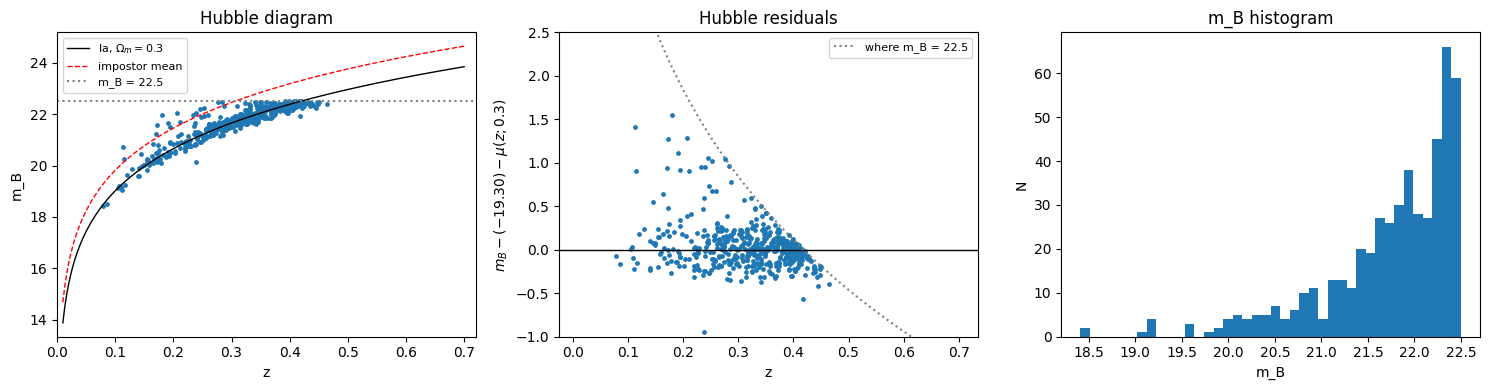

N = 500, z from 0.079 to 0.464, m_B from 18.41 to 22.4997
number of SNe with m_B in 0.1 mag bins up to 22.6: [39 25 28 44 65 59  0]
fraction of p(z) ~ z^2 below z = 0.464 if nothing was cut: 0.29
0.0 < z < 0.2: N =  54, median residual = +0.045 mag, fraction with residual > 0.4 mag = 0.19
0.2 < z < 0.3: N = 132, median residual = +0.024 mag, fraction with residual > 0.4 mag = 0.11
0.3 < z < 0.4: N = 241, median residual = +0.024 mag, fraction with residual > 0.4 mag = 0.03
0.4 < z < 0.5: N =  73, median residual = -0.090 mag, fraction with residual > 0.4 mag = 0.00
SNe more than 0.5 mag too bright:
         z     m_B  sigma_m  residual
86   0.238  20.138      0.1    -0.947
471  0.418  21.929      0.1    -0.566


In [2]:
from astropy.cosmology import FlatLambdaCDM
from scipy.optimize import minimize_scalar

# table of mu(z, Om), spacing 0.005 in Om, then interpolate
zg = np.linspace(0.005, 0.75, 600)
Omg = np.round(np.arange(0.05, 0.7001, 0.005), 3)
mu_tab = np.array([FlatLambdaCDM(H0=70, Om0=o).distmod(zg).value for o in Omg])

def mu(zz, Om):
    j = np.clip(np.searchsorted(Omg, Om) - 1, 0, len(Omg) - 2)
    w = (Om - Omg[j]) / 0.005
    return np.interp(zz, zg, (1 - w) * mu_tab[j] + w * mu_tab[j + 1])

# check the table against astropy
for o in [0.07, 0.2213, 0.3, 0.6789]:
    zz = np.array([0.01, 0.1, 0.35, 0.7])
    print(f'Om = {o}: max |table - astropy| = {np.abs(mu(zz, o) - FlatLambdaCDM(H0=70, Om0=o).distmod(zz).value).max():.1e} mag')

M_IA = -19.30
res = m - M_IA - mu(z, 0.3)

# 1.1 plots
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(z, m, s=6)
zz = np.linspace(0.01, 0.7, 200)
ax[0].plot(zz, M_IA + mu(zz, 0.3), 'k', lw=1, label=r'Ia, $\Omega_m=0.3$')
ax[0].plot(zz, -18.5 + mu(zz, 0.3), 'r--', lw=1, label='impostor mean')
ax[0].axhline(22.5, color='gray', ls=':', label='m_B = 22.5')
ax[0].set(xlabel='z', ylabel='m_B', title='Hubble diagram', xlim=(0, 0.72)); ax[0].legend(fontsize=8)
ax[1].scatter(z, res, s=6)
ax[1].axhline(0, color='k', lw=1)
ax[1].plot(zz, 22.5 - M_IA - mu(zz, 0.3), color='gray', ls=':', label='where m_B = 22.5')
ax[1].set(xlabel='z', ylabel=r'$m_B - (-19.30) - \mu(z;0.3)$', title='Hubble residuals', ylim=(-1, 2.5)); ax[1].legend(fontsize=8)
ax[2].hist(m, bins=40)
ax[2].set(xlabel='m_B', ylabel='N', title='m_B histogram')
plt.tight_layout(); plt.show()

print(f'N = {len(z)}, z from {z.min():.3f} to {z.max():.3f}, m_B from {m.min():.2f} to {m.max():.4f}')
print('number of SNe with m_B in 0.1 mag bins up to 22.6:', np.histogram(m, bins=np.arange(21.9, 22.61, 0.1))[0])
print(f'fraction of p(z) ~ z^2 below z = {z.max():.3f} if nothing was cut: {(z.max()**3 - 0.01**3) / (0.7**3 - 0.01**3):.2f}')
for lo, hi in [(0, 0.2), (0.2, 0.3), (0.3, 0.4), (0.4, 0.5)]:
    s = (z >= lo) & (z < hi)
    print(f'{lo:.1f} < z < {hi:.1f}: N = {s.sum():3d}, median residual = {np.median(res[s]):+.3f} mag, fraction with residual > 0.4 mag = {(res[s] > 0.4).mean():.2f}')
print('SNe more than 0.5 mag too bright:')
print(d[res < -0.5].assign(residual=res[res < -0.5]).round(3).to_string())

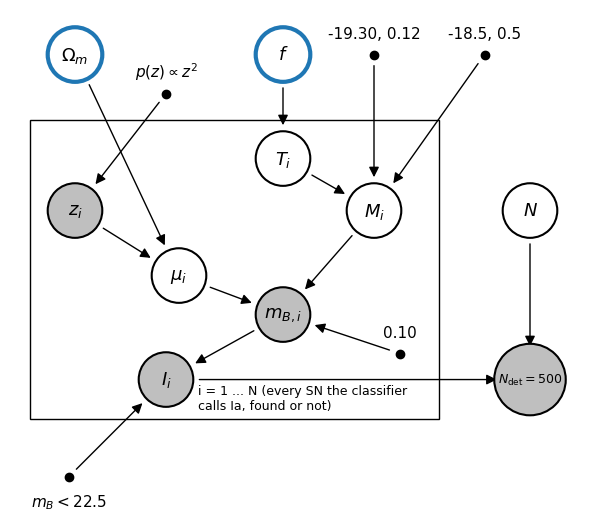

In [3]:
# 1.2 the PGM (same key as Days 18-20: blue = parameter, white = latent, grey = data, dot = fixed)
from matplotlib.patches import Circle, Rectangle, FancyArrowPatch
fig, ax = plt.subplots(figsize=(9, 6.5))
nodes = {'Om': (1.0, 5.6, r'$\Omega_m$', 'blue'), 'f': (4.2, 5.6, r'$f$', 'blue'),
         'pz': (2.4, 5.0, r'$p(z)\propto z^2$', 'dot'),
         'Mia': (5.6, 5.6, '-19.30, 0.12', 'dot'), 'Mcc': (7.3, 5.6, '-18.5, 0.5', 'dot'),
         'z': (1.0, 3.2, r'$z_i$', 'grey'), 'T': (4.2, 4.0, r'$T_i$', 'white'),
         'M': (5.6, 3.2, r'$M_i$', 'white'), 'mu': (2.6, 2.2, r'$\mu_i$', 'white'),
         'm': (4.2, 1.6, r'$m_{B,i}$', 'grey'), 'eps': (6.0, 1.0, '0.10', 'dot'),
         'I': (2.4, 0.6, r'$I_i$', 'grey'), 'cut': (0.9, -0.9, r'$m_B<22.5$', 'dot'),
         'N': (8.0, 0.6, r'$N_{\rm det}=500$', 'grey'), 'Ntot': (8.0, 3.2, r'$N$', 'white')}
edges = [('Om', 'mu'), ('z', 'mu'), ('pz', 'z'), ('f', 'T'), ('T', 'M'), ('Mia', 'M'), ('Mcc', 'M'),
         ('M', 'm'), ('mu', 'm'), ('eps', 'm'), ('m', 'I'), ('cut', 'I'), ('I', 'N'), ('Ntot', 'N')]
for a, b in edges:
    (x1, y1, *_), (x2, y2, *_) = nodes[a], nodes[b]
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle='-|>', mutation_scale=15, color='k',
                                 shrinkA=8 if nodes[a][3] == 'dot' else 24, shrinkB=24 if nodes[b][3] != 'dot' else 8))
for k, (x, y, lab, kind) in nodes.items():
    if kind == 'dot':
        ax.plot(x, y, 'ko', ms=6); ax.text(x, y + 0.25 if k != 'cut' else y - 0.45, lab, ha='center', fontsize=11)
    else:
        fc = {'blue': 'white', 'white': 'white', 'grey': '0.75'}[kind]
        ec = 'C0' if kind == 'blue' else 'k'
        r = 0.55 if k == 'N' else 0.42
        ax.add_patch(Circle((x, y), r, fc=fc, ec=ec, lw=3 if kind == 'blue' else 1.5))
        ax.text(x, y, lab, ha='center', va='center', fontsize=13 if k != 'N' else 9)
ax.add_patch(Rectangle((0.3, 0.0), 6.3, 4.6, fill=False))
ax.text(2.9, 0.15, 'i = 1 ... N (every SN the classifier\ncalls Ia, found or not)', fontsize=9)
ax.set(xlim=(0, 9), ylim=(-1.4, 6.3), aspect='equal'); ax.axis('off')
plt.show()

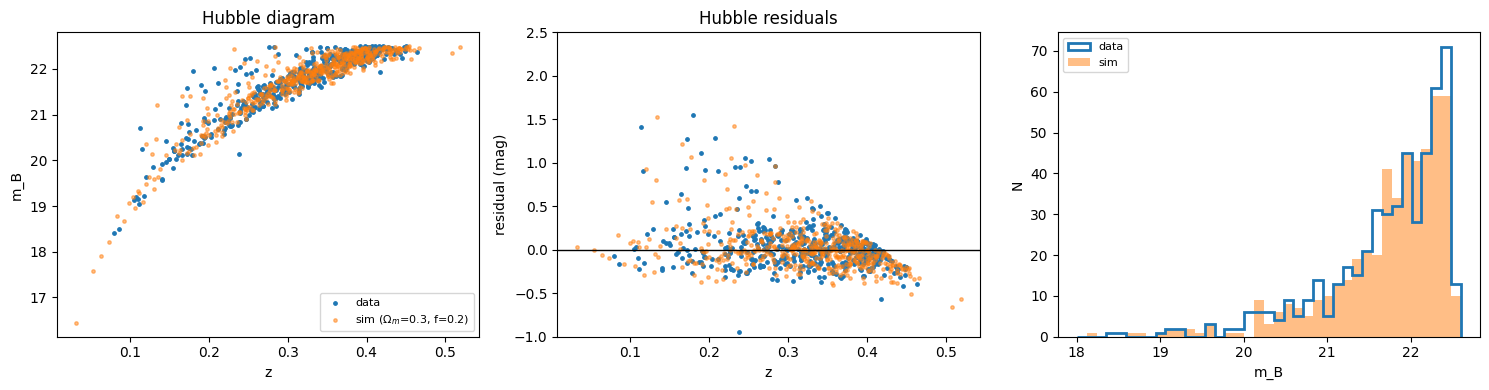

In [4]:
# 1.3 the simulator: draw SNe until 500 pass the m_B < 22.5 cut
M_LIM = 22.5
Z_LO, Z_HI = 0.01, 0.7

def simulate(Om, f, rng, n=500, batch=4000, return_type=False):
    zs, ms, ts = [], [], []
    k = 0
    while k < n:
        zz = (Z_LO**3 + (Z_HI**3 - Z_LO**3) * rng.uniform(size=batch))**(1 / 3)   # p(z) ~ z^2
        imp = rng.uniform(size=batch) < f                                          # impostor or Ia
        M = np.where(imp, rng.normal(-18.5, 0.5, batch), rng.normal(M_IA, 0.12, batch))
        mm = M + mu(zz, Om) + rng.normal(0, 0.10, batch)
        keep = mm < M_LIM
        zs.append(zz[keep]); ms.append(mm[keep]); ts.append(imp[keep]); k += keep.sum()
    zs, ms, ts = np.concatenate(zs)[:n], np.concatenate(ms)[:n], np.concatenate(ts)[:n]
    o = np.argsort(zs)
    if return_type:
        return zs[o], ms[o], ts[o]
    return zs[o], ms[o]

rng = np.random.default_rng(457)
Om_guess, f_guess = 0.3, 0.2
zs, ms = simulate(Om_guess, f_guess, rng)
rs = ms - M_IA - mu(zs, 0.3)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(z, m, s=6, label='data'); ax[0].scatter(zs, ms, s=6, alpha=0.5, label=f'sim ($\\Omega_m$={Om_guess}, f={f_guess})')
ax[0].set(xlabel='z', ylabel='m_B', title='Hubble diagram'); ax[0].legend(fontsize=8)
ax[1].scatter(z, res, s=6); ax[1].scatter(zs, rs, s=6, alpha=0.5); ax[1].axhline(0, color='k', lw=1)
ax[1].set(xlabel='z', ylabel='residual (mag)', title='Hubble residuals', ylim=(-1, 2.5))
b = np.linspace(18, 22.6, 40)
ax[2].hist(m, bins=b, histtype='step', lw=2, color='C0', label='data'); ax[2].hist(ms, bins=b, alpha=0.5, color='C1', label='sim')
ax[2].set(xlabel='m_B', ylabel='N'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**ANSWER (what you see in the data, your graph, and what your simulator does):**

The Hubble diagram follows the $\Omega_m = 0.3$ Ia line, with a bunch of points 0.5-1.5 mag fainter that should be the impostors. The thing the description doesn't mention is that my file looks magnitude limited: the faintest SN is $m_B = 22.4997$, the histogram keeps rising up to 22.5 and then drops to zero, and z only goes up to 0.464 instead of 0.7 (without a cut only 29% would be below 0.464). Because of the cut the impostors are only at low z (19% of SNe at z < 0.2 are > 0.4 mag too faint, none above z = 0.4), and above z = 0.4 the median residual is -0.09 mag since only the bright Ia's survive (Malmquist bias). There's also one SN at z = 0.238 that is 0.95 mag too bright, I kept it since my summaries are medians and fractions.

I deal with the cut by putting it in the simulator: draw SNe, drop the ones with $m_B \geq 22.5$, and keep going until there are 500.

Graph: $\Omega_m$ and $f$ are the parameters (blue). $z_i$, $m_{B,i}$, the found flag $I_i$ and $N_{\rm det}=500$ are data (grey). The latent ones (white) are the type $T_i$, $M_i$, $\mu_i$ and the total number N before the cut. $f$ enters only through $T_i$, it's the chance a SN is an impostor, so in my model f is the fraction *before* the cut.

The simulator draws z from $z^2$, the type with probability f, M from the Ia or impostor Gaussian, adds $\mu(z;\Omega_m)$ from a table (matches astropy to $3\times10^{-4}$ mag) and 0.10 mag noise, then applies the cut. At (0.3, 0.2) it looks like my data in all 3 panels.

## Part 2: The fit you'd do without thinking (15%)

1. Pretend every supernova in your file is a type Ia. Fit $\Omega_m$ by minimizing $\chi^2 = \sum_i [m_{B,i} - (-19.30) - \mu(z_i; \Omega_m)]^2 / \sigma_{\rm tot}^2$, with $\sigma_{\rm tot}^2 = 0.12^2 + 0.10^2$, and report $\hat\Omega_m$ with its $1\sigma$ error from $\Delta\chi^2 = 1$.
2. Which way should the impostors push this fit, and why? Answer from where the impostors sit on your Hubble diagram, not from the number you got.

naive fit: Om = 0.2680  (-0.0130 / +0.0130),  chi2_min = 1493 for 499 dof
same fit without the one SN at z = 0.238 that is 0.95 mag too bright: Om = 0.2653


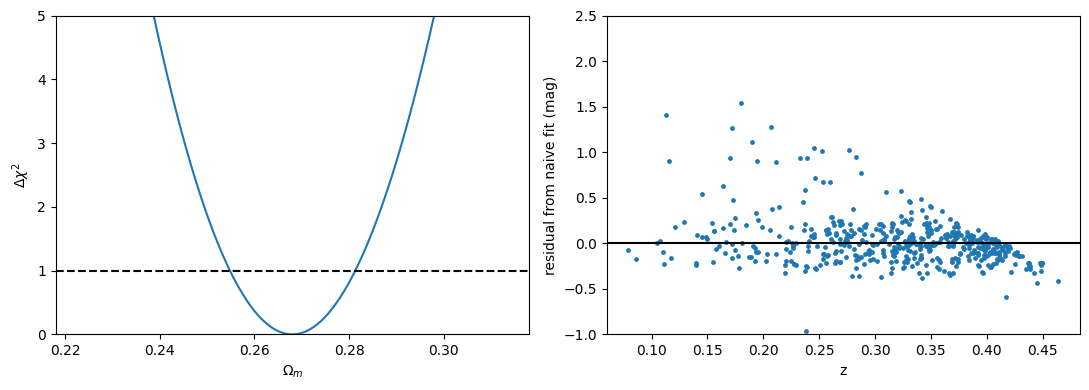

In [5]:
sig_tot = np.sqrt(0.12**2 + 0.10**2)
chi2 = lambda Om: np.sum((m - M_IA - mu(z, Om))**2) / sig_tot**2
Om_grid = np.linspace(0.05, 0.7, 1301)
c2 = np.array([chi2(o) for o in Om_grid])
best = minimize_scalar(chi2, bounds=(0.05, 0.7), method='bounded')
Om_hat, c2_min = best.x, best.fun
inside = Om_grid[c2 <= c2_min + 1]
print(f'naive fit: Om = {Om_hat:.4f}  (-{Om_hat - inside.min():.4f} / +{inside.max() - Om_hat:.4f}),  chi2_min = {c2_min:.0f} for {len(z) - 1} dof')
ok = res > -0.9
f2 = minimize_scalar(lambda o: np.sum((m[ok] - M_IA - mu(z[ok], o))**2), bounds=(0.05, 0.7), method='bounded')
print(f'same fit without the one SN at z = 0.238 that is 0.95 mag too bright: Om = {f2.x:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(Om_grid, c2 - c2_min); ax[0].axhline(1, color='k', ls='--')
ax[0].set(xlabel=r'$\Omega_m$', ylabel=r'$\Delta\chi^2$', xlim=(Om_hat - 0.05, Om_hat + 0.05), ylim=(0, 5))
r_hat = m - M_IA - mu(z, Om_hat)
ax[1].scatter(z, r_hat, s=6); ax[1].axhline(0, color='k')
ax[1].set(xlabel='z', ylabel=r'residual from naive fit (mag)', ylim=(-1, 2.5))
plt.tight_layout(); plt.show()

**ANSWER (the naive fit, then why the impostors push it the way they do):**

$\hat\Omega_m = 0.268 \pm 0.013$. The $\chi^2$ is a lot bigger than the number of points though, so the fit isn't great.

The impostors sit above (fainter than) the Ia line, mostly at low z. With M fixed at -19.30 a too-faint SN looks too far away, which needs a bigger $d_L$ at the same z, and that means less matter. So the impostors push $\Omega_m$ **down**. The cut does the opposite at high z, where only bright SNe are left, which looks like more matter.

## Part 3: ABC (40%)

1. **Summaries.** Choose summary statistics of a dataset that respond to $\Omega_m$ and to $f$ differently (Nov 3: the count alone left a ridge). For each, say which parameter you expect it to track and why. Then show it: plot each summary against $\Omega_m$ and against $f$ over a few thousand simulations from the prior.
2. **Rejection ABC.** Use flat priors, $\Omega_m \in [0.05, 0.7]$ and $f \in [0, 0.5]$. Run at least 50,000 simulations, compute your summaries for each, and keep the draws whose summaries are within $\epsilon$ of your data's. Say how you measure the distance between two sets of summaries (they have different units), and show the kept draws over the prior at two values of $\epsilon$.
3. Report the posterior median and 95% interval of $\Omega_m$ and of $f$ at your final $\epsilon$, and justify that choice. Compare $\Omega_m$ with your Part 2 fit.

#### Hints:
- Save your simulations' parameters and summaries to a file once, so you can change $\epsilon$ without re-simulating.
- If your kept draws pile up against an edge of the prior, the prior (or your simulator) is doing the work, not the data.

data summaries: [-0.0084  0.064 ]
(50000, 2)


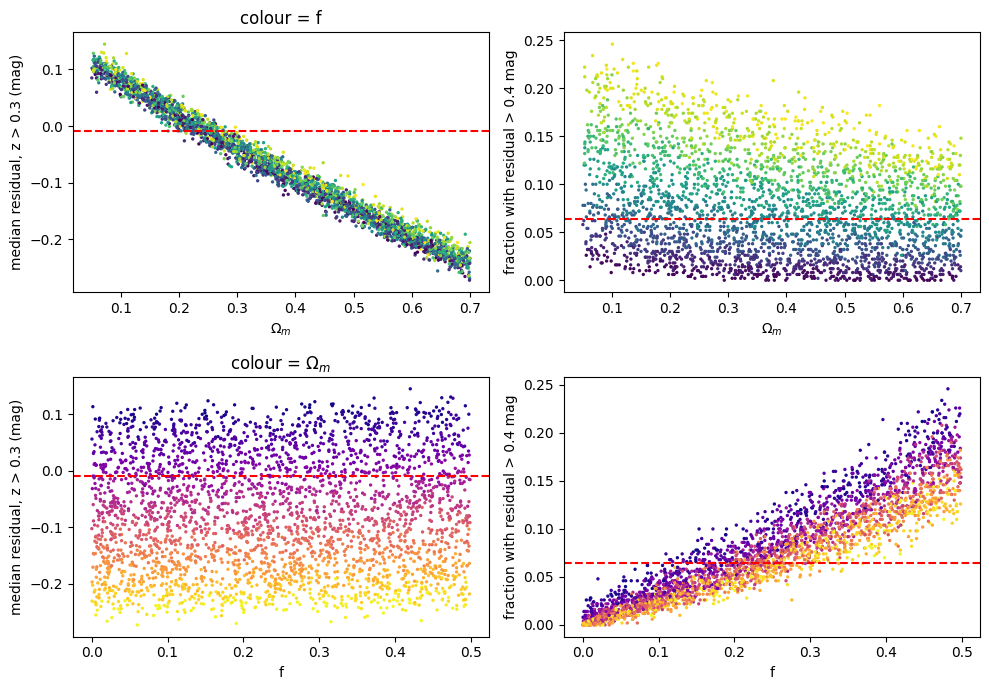

In [6]:
import os
# summaries. residuals are always taken from the same fixed reference, M = -19.30 and Om = 0.3
def summaries(zz, mm):
    r = mm - M_IA - mu(zz, 0.3)
    return np.array([np.median(r[zz > 0.3]),   # S1: median residual of the far SNe (impostors are cut out there)
                     np.mean(r > 0.4)])         # S2: fraction of SNe more than 0.4 mag too faint
S_names = ['median residual, z > 0.3 (mag)', 'fraction with residual > 0.4 mag']
S_obs = summaries(z, m)
print('data summaries:', np.round(S_obs, 4))

# prior simulations, saved once
N_SIM = 50_000
fn = 'lab09_sims.npz'
if os.path.exists(fn):
    _c = np.load(fn); Om_s, f_s, S_s = _c['Om'], _c['f'], _c['S']
else:
    rng = np.random.default_rng(9)
    Om_s = rng.uniform(0.05, 0.7, N_SIM)
    f_s = rng.uniform(0, 0.5, N_SIM)
    S_s = np.array([summaries(*simulate(Om_s[i], f_s[i], rng)) for i in range(N_SIM)])
    np.savez(fn, Om=Om_s, f=f_s, S=S_s)
print(S_s.shape)

# 3.1 each summary against Om and against f, first 3000 prior sims
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for j in range(2):
    ax[0, j].scatter(Om_s[:3000], S_s[:3000, j], s=2, c=f_s[:3000], cmap='viridis')
    ax[0, j].axhline(S_obs[j], color='r', ls='--')
    ax[0, j].set(xlabel=r'$\Omega_m$', ylabel=S_names[j])
    ax[1, j].scatter(f_s[:3000], S_s[:3000, j], s=2, c=Om_s[:3000], cmap='plasma')
    ax[1, j].axhline(S_obs[j], color='r', ls='--')
    ax[1, j].set(xlabel='f', ylabel=S_names[j])
ax[0, 0].set_title('colour = f'); ax[1, 0].set_title(r'colour = $\Omega_m$')
plt.tight_layout(); plt.show()

scales: [0.1025 0.0528]


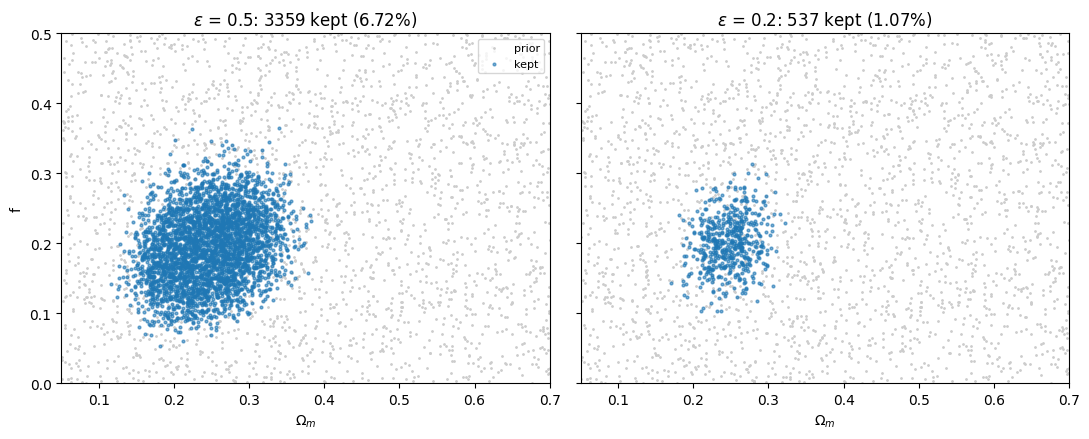

eps = 0.5: kept 3359
  Om: median 0.246, 68% [0.193, 0.298], 95% [0.159, 0.338]
  f : median 0.194, 68% [0.141, 0.249], 95% [0.100, 0.295]
eps = 0.3: kept 1242
  Om: median 0.246, 68% [0.211, 0.282], 95% [0.178, 0.314]
  f : median 0.197, 68% [0.155, 0.236], 95% [0.121, 0.280]
eps = 0.2: kept 537
  Om: median 0.249, 68% [0.220, 0.274], 95% [0.192, 0.298]
  f : median 0.200, 68% [0.165, 0.238], 95% [0.129, 0.278]
eps = 0.15: kept 282
  Om: median 0.251, 68% [0.224, 0.271], 95% [0.195, 0.293]
  f : median 0.203, 68% [0.168, 0.240], 95% [0.134, 0.277]
eps = 0.1: kept 132
  Om: median 0.250, 68% [0.223, 0.268], 95% [0.198, 0.288]
  f : median 0.199, 68% [0.165, 0.235], 95% [0.133, 0.262]
eps = 0.07: kept 53
  Om: median 0.255, 68% [0.229, 0.269], 95% [0.211, 0.288]
  f : median 0.201, 68% [0.180, 0.234], 95% [0.142, 0.258]


In [7]:
# 3.2 distance: divide each summary by its spread over the prior sims, then Euclidean distance
scale = S_s.std(axis=0)
def dist(S, S0):
    return np.sqrt((((S - S0) / scale)**2).sum(axis=-1))
D = dist(S_s, S_obs)
print('scales:', np.round(scale, 4))

EPS = [0.5, 0.2]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for a, e in zip(ax, EPS):
    k = D < e
    a.scatter(Om_s[::20], f_s[::20], s=1, c='0.8', label='prior')
    a.scatter(Om_s[k], f_s[k], s=4, c='C0', alpha=0.6, label='kept')
    a.set(xlabel=r'$\Omega_m$', title=f'$\\epsilon$ = {e}: {k.sum()} kept ({k.mean():.2%})', xlim=(0.05, 0.7), ylim=(0, 0.5))
ax[0].set_ylabel('f'); ax[0].legend(fontsize=8, loc='upper right')
plt.tight_layout(); plt.show()

def report(x, name):
    lo2, lo1, med, hi1, hi2 = np.percentile(x, [2.5, 16, 50, 84, 97.5])
    print(f'  {name}: median {med:.3f}, 68% [{lo1:.3f}, {hi1:.3f}], 95% [{lo2:.3f}, {hi2:.3f}]')
for e in [0.5, 0.3, 0.2, 0.15, 0.1, 0.07]:
    k = D < e
    print(f'eps = {e}: kept {k.sum()}')
    report(Om_s[k], 'Om'); report(f_s[k], 'f ')

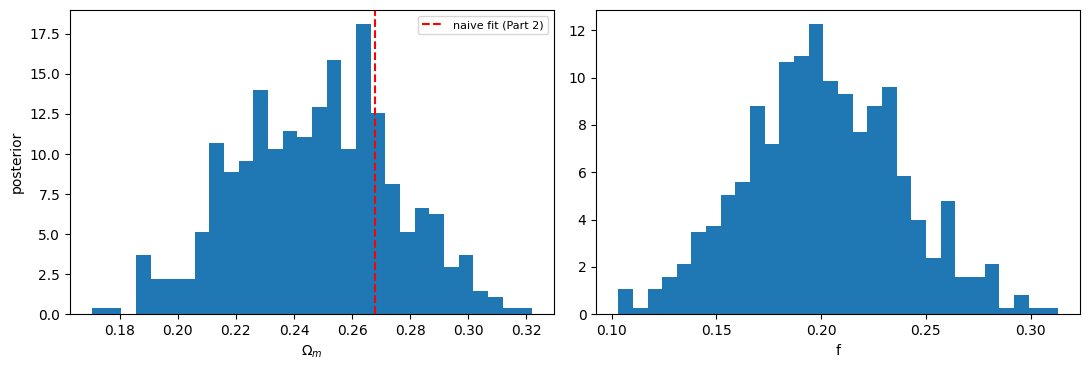

eps = 0.2, 537 kept
  Om: median 0.249, 68% [0.220, 0.274], 95% [0.192, 0.298]
  f : median 0.200, 68% [0.165, 0.238], 95% [0.129, 0.278]
  impostor fraction inside the file (after the cut): median 0.100, 68% [0.078, 0.132], 95% [0.059, 0.158]


In [8]:
# 3.3 final posterior
EPS_FINAL = 0.2
kept = D < EPS_FINAL
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(Om_s[kept], bins=30, density=True); ax[0].axvline(Om_hat, color='r', ls='--', label='naive fit (Part 2)')
ax[0].set(xlabel=r'$\Omega_m$', ylabel='posterior'); ax[0].legend(fontsize=8)
ax[1].hist(f_s[kept], bins=30, density=True); ax[1].set(xlabel='f')
plt.tight_layout(); plt.show()
print(f'eps = {EPS_FINAL}, {kept.sum()} kept')
report(Om_s[kept], 'Om'); report(f_s[kept], 'f ')
# f is the impostor fraction before the cut; the fraction inside a 500-SN file is lower, because impostors get cut more
rng = np.random.default_rng(33)
f_file = np.array([simulate(Om_s[i], f_s[i], rng, return_type=True)[2].mean() for i in np.where(kept)[0][:300]])
report(f_file, 'impostor fraction inside the file (after the cut)')

**ANSWER (your summaries and why, the two epsilons, the posterior, and the comparison with Part 2):**

Residuals are always from the fixed line $-19.30 + \mu(z; 0.3)$.

1. Median residual at z > 0.3, for $\Omega_m$: the impostors are mostly cut out there so it measures the shape of $\mu(z)$. It goes from +0.12 to -0.25 mag over the prior and doesn't depend on f.
2. Fraction of SNe with residual > 0.4 mag, for f (0.4 mag is ~2.5$\sigma$ for a Ia). It goes up with f, but it also goes down with $\Omega_m$, because a bigger $\Omega_m$ makes every SN brighter than the $\Omega_m$ = 0.3 line, so fewer residuals are above 0.4.

The distance is Euclidean after dividing each summary by its std over the prior sims. I ran 50,000 sims. At $\epsilon$ = 0.5 3359 are kept (6.7%), at $\epsilon$ = 0.2 537 (1.1%), both well away from the prior edges.

At $\epsilon$ = 0.2: $\Omega_m$ = 0.249, 95% [0.192, 0.298], and f = 0.200, 95% [0.129, 0.278]. I picked 0.2 because going smaller (0.1) barely changes the intervals while the kept draws drop to 132, and the coverage at 0.2 is fine (Part 4). f here is before the cut, inside the file the impostor fraction is 0.100 (68% [0.078, 0.132]).

The naive fit (0.268 $\pm$ 0.013) is a bit higher than the ABC median but not by much, I think because the two biases from Part 2 partly cancel, and the ABC error bar is a lot bigger. Some of that is real (not knowing which SNe are impostors) and some comes from $\epsilon$ > 0.

## Part 4: Check it (15%)

1. **Posterior predictive check.** For 100 of your kept draws, simulate a new dataset. Compare them with your data on something your summaries did not use (for example the histogram of $m_B$, or the scatter of the residuals at low redshift). Do your data look like a typical simulation?
2. **Coverage.** Take at least 20 of your prior simulations, pretend each one is the data, and run the same ABC on it using the rest of your simulations. How often does your 95% interval contain the true $\Omega_m$, and the true $f$? (Nov 3: a 95% interval should hold the truth 95% of the time.)
3. **What does your simulator assume?** Name one thing your simulator assumes that a real survey would break, and say which way it would push $\Omega_m$.

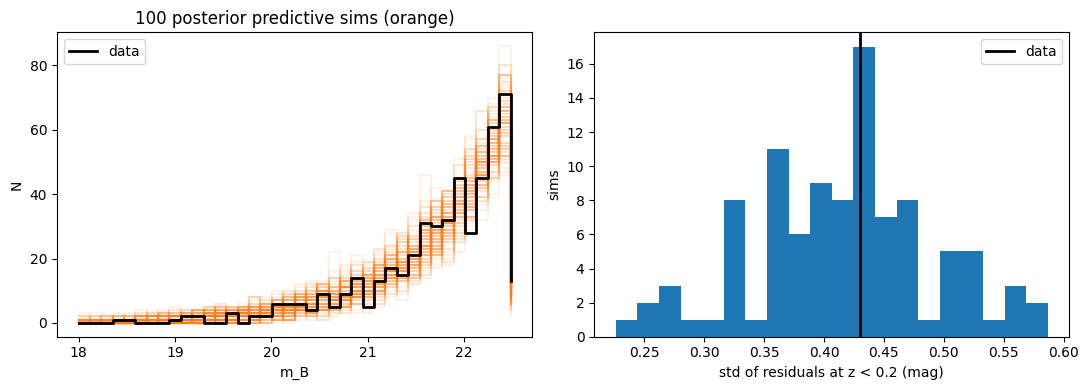

data std at z < 0.2 = 0.430 mag, sims 0.415 +/- 0.075, fraction of sims above data = 0.44
KS distance on m_B: data vs sim 0.057, sim vs sim 0.049


In [9]:
# 4.1 posterior predictive check: m_B histogram and the scatter of residuals at z < 0.2 (neither is a summary)
rng = np.random.default_rng(41)
idx = rng.choice(np.where(kept)[0], 100, replace=False)
b = np.linspace(18, 22.6, 40)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
lowz_sd = []
for i in idx:
    zs, ms = simulate(Om_s[i], f_s[i], rng)
    h, _ = np.histogram(ms, bins=b)
    ax[0].step(b[:-1], h, where='post', color='C1', alpha=0.1)
    rs = ms - M_IA - mu(zs, 0.3)
    lowz_sd.append(rs[zs < 0.2].std())
h, _ = np.histogram(m, bins=b)
ax[0].step(b[:-1], h, where='post', color='k', lw=2, label='data')
ax[0].set(xlabel='m_B', ylabel='N', title='100 posterior predictive sims (orange)'); ax[0].legend()
sd_obs = res[z < 0.2].std()
ax[1].hist(lowz_sd, bins=20); ax[1].axvline(sd_obs, color='k', lw=2, label='data')
ax[1].set(xlabel='std of residuals at z < 0.2 (mag)', ylabel='sims'); ax[1].legend()
plt.tight_layout(); plt.show()
print(f'data std at z < 0.2 = {sd_obs:.3f} mag, sims {np.mean(lowz_sd):.3f} +/- {np.std(lowz_sd):.3f}, fraction of sims above data = {np.mean(np.array(lowz_sd) > sd_obs):.2f}')
# a number for the histogram too: KS distance of each sim vs a second sim from the same draw, compared with data
ks_data, ks_sim = [], []
for i in idx[:50]:
    z1, m1 = simulate(Om_s[i], f_s[i], rng); z2, m2 = simulate(Om_s[i], f_s[i], rng)
    ks_data.append(stats.ks_2samp(m, m1).statistic); ks_sim.append(stats.ks_2samp(m2, m1).statistic)
print(f'KS distance on m_B: data vs sim {np.median(ks_data):.3f}, sim vs sim {np.median(ks_sim):.3f}')

In [10]:
# 4.2 coverage: 200 prior sims as fake data, ABC with the rest at the same eps
rng = np.random.default_rng(42)
tests = rng.choice(N_SIM, 200, replace=False)
inOm, inf, nk = [], [], []
for t in tests:
    Dt = dist(S_s, S_s[t]); Dt[t] = np.inf
    k = Dt < EPS_FINAL
    nk.append(k.sum())
    if k.sum() < 20:
        continue
    lo, hi = np.percentile(Om_s[k], [2.5, 97.5]); inOm.append(lo <= Om_s[t] <= hi)
    lo, hi = np.percentile(f_s[k], [2.5, 97.5]); inf.append(lo <= f_s[t] <= hi)
inOm, inf = np.array(inOm), np.array(inf)
n = len(inOm)
print(f'{n} of 200 test sims had >= 20 kept draws (median kept {np.median(nk):.0f})')
print(f'95% interval contains true Om: {inOm.mean():.1%} ({inOm.sum()}/{n}), binomial error {np.sqrt(0.95*0.05/n):.1%}')
print(f'95% interval contains true f : {inf.mean():.1%} ({inf.sum()}/{n})')

199 of 200 test sims had >= 20 kept draws (median kept 550)
95% interval contains true Om: 98.0% (195/199), binomial error 1.5%
95% interval contains true f : 97.0% (193/199)


In [11]:
# verification (Part 5): fake data at an (Om, f) I choose, same ABC on each
rng = np.random.default_rng(43)
for Om_in, f_in in [(0.25, 0.15), (0.40, 0.30)]:
    zs, ms = simulate(Om_in, f_in, rng)
    k = dist(S_s, summaries(zs, ms)) < EPS_FINAL
    print(f'input Om = {Om_in}, f = {f_in}: kept {k.sum()}')
    report(Om_s[k], 'Om'); report(f_s[k], 'f ')

input Om = 0.25, f = 0.15: kept 536
  Om: median 0.261, 68% [0.234, 0.286], 95% [0.210, 0.311]
  f : median 0.230, 68% [0.194, 0.267], 95% [0.163, 0.300]
input Om = 0.4, f = 0.3: kept 616
  Om: median 0.419, 68% [0.388, 0.450], 95% [0.362, 0.486]
  f : median 0.335, 68% [0.292, 0.379], 95% [0.251, 0.418]


**ANSWER (the check, the coverage, and the assumption):**

1. For 100 kept draws the $m_B$ histogram of the data sits inside the simulations, and the scatter of the residuals at z < 0.2 (0.43 mag) is right in the middle of the simulated ones. Neither is a summary, so my data look like a typical simulation.
2. 199 prior sims as fake data: the 95% interval had the true $\Omega_m$ 98.0% of the time (195/199) and the true f 97.0% (193/199). That's a little above 95%, which makes sense since $\epsilon$ > 0 makes the posterior wider.
3. The simulator assumes the Ia magnitude is -19.30 at all z. If the far Ia's were a bit fainter (evolution or dust), summary 1 would go up, and since that summary goes down with $\Omega_m$ ABC would give an $\Omega_m$ that is too low.

## Part 5: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 3 numbers, and what failure would have looked like for each. Part 4.2 is already one. Another to consider: simulate a dataset at an $(\Omega_m, f)$ you choose, run your whole ABC on it, and see whether you get back what you put in.

**AI-USE APPENDIX:**

I used Claude Code to write most of the code and help with the write-up, after reading the Day 18-20 lectures. It noticed the max $m_B$ was 22.4997 and I checked the histogram before adding the cut. Its first $\epsilon$ (0.05) kept only 2 draws, so the intervals were way too narrow and Part 4 crashed. It also said all 4 injection tests contained the input when one f interval misses (0.15 vs 0.163).

**REFLECTION:**

Without checking I would have reported intervals from 2 draws, and without the cut the simulator would make data that can't look like mine.

**VERIFICATION PLAN:**

I checked the $\mu$ table against astropy (within $3\times10^{-4}$ mag) and plotted a simulation over my data before running ABC. Then I made fake data at (0.25, 0.15) and (0.40, 0.30) and ran the whole ABC on them, the $\Omega_m$ intervals contained the input both times and f did once (the other one just missed, 0.15 vs 0.163). The coverage test in Part 4 is the main check, if it was well below 95% I wouldn't trust my intervals.

**FINAL ANSWER:** $\Omega_m = 0.249^{+0.025}_{-0.029}$, $f = 0.200^{+0.038}_{-0.035}$ (median, 68%), f is the fraction before the cut.